# Етап 6 — Гібридна (fusion) модель

Мета: об'єднати поведінковий сигнал (модель 02, рух миші) і мережевий
сигнал (модель 03, мережевий трафік) в одну гібридну систему виявлення
ботів.

## ⚠️ Головне методологічне обмеження — прочитати перед запуском

Поведінкові дані (DELBOT-Mouse/CaptchaSolve30k) і мережеві дані
(CIC/UNSW/CTU-13) — це ДВА ПОВНІСТЮ НЕЗАЛЕЖНІ датасети. Жодна сесія не
має одночасно і траєкторії миші, і мережевого потоку від того самого
джерела. Тому буквальний fusion "для кожного реального прикладу є обидва
сигнали" на наявних даних НЕМОЖЛИВИЙ.

Використаний тут підхід — стандартна практика з літератури з
мультимодальної біометрії за відсутності парного датасету: симулюємо пари
(score_behavioral, score_network), незалежно семплуючи ймовірність з
кожної моделі окремо В МЕЖАХ ТОГО САМОГО КЛАСУ (людина/норма або
бот/атака), припускаючи умовну незалежність двох модальностей за умови
істинного класу. Це ЧЕСНА ДЕМОНСТРАЦІЯ МЕХАНІКИ fusion під явним
припущенням, А НЕ валідована на реальних парних даних оцінка точності.
Для реального розгортання знадобився б справжній парний датасет (одна
сесія з одночасним записом і руху миші, і мережевого трафіку) — цього
дослідження це виходить за межі.

Мережевий компонент — CTU-13 (єдиний мережевий датасет із міткою саме
"Botnet vs Normal", а не загальні типи атак — концептуально найближчий
до теми "людина проти бота").

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

!pip install -q xgboost

import os
import glob
import numpy as np
import pandas as pd
import joblib
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (classification_report, confusion_matrix,
                              accuracy_score, precision_score, recall_score, f1_score)

PROJECT_DIR = '/content/drive/MyDrive/man-bot-detection'
OUTPUT_DIR = os.path.join(PROJECT_DIR, 'notebooks/results')
os.makedirs(os.path.join(OUTPUT_DIR, 'figures'), exist_ok=True)
os.makedirs(os.path.join(OUTPUT_DIR, 'tables'), exist_ok=True)

RANDOM_STATE = 42

Mounted at /content/drive


## Частина A. Поведінковий сигнал — тестові ймовірності з моделі 02

Відтворюємо ТОЙ САМИЙ train_test_split (random_state=42), що й у 02, щоб
отримати справжню (не бачену моделлю) тестову вибірку, і рахуємо
ймовірність класу "бот" для кожного тестового вікна вже навченою моделлю
`behavioral_rf_300.pkl`.

In [ ]:
FEATURE_COLS_BEHAV = ['mean_speed', 'max_speed', 'std_speed', 'path_length',
                       'num_stops', 'mean_angle', 'num_clicks', 'num_points']

behav_csv = f'{PROJECT_DIR}/data/processed/behavioral_features_windowed.csv'
df_behav = pd.read_csv(behav_csv)
print(f"Завантажено ознак (02): {df_behav.shape[0]} рядків")

X_behav = df_behav[FEATURE_COLS_BEHAV]
y_behav = df_behav['label']

X_behav_train, X_behav_test, y_behav_train, y_behav_test = train_test_split(
    X_behav, y_behav, test_size=0.2, stratify=y_behav, random_state=RANDOM_STATE
)

rf_behav = joblib.load(f'{PROJECT_DIR}/models/behavioral_rf_300.pkl')
proba_behav_test = rf_behav.predict_proba(X_behav_test)[:, list(rf_behav.classes_).index('bot')]

print(f"Тестова вибірка (02): {len(X_behav_test)} вікон "
      f"(bot={sum(y_behav_test=='bot')}, human={sum(y_behav_test=='human')})")

behav_scores_by_class = {
    'bot': proba_behav_test[(y_behav_test == 'bot').values],
    'human': proba_behav_test[(y_behav_test == 'human').values],
}
print(f"Розподіл proba(bot) для справжніх ботів:    "
      f"mean={behav_scores_by_class['bot'].mean():.4f}")
print(f"Розподіл proba(bot) для справжніх людей:     "
      f"mean={behav_scores_by_class['human'].mean():.4f}")

Завантажено ознак (02): 39224 рядків
Тестова вибірка (02): 7845 вікон (bot=633, human=7212)
Розподіл proba(bot) для справжніх ботів:    mean=0.7880
Розподіл proba(bot) для справжніх людей:     mean=0.0157


## Частина B. Мережевий сигнал — тестові ймовірності на CTU-13

CTU-13 не має збереженої моделі з 03 (там моделі не зберігались на диск),
тому тут швидко перенавчаємо RandomForest на тих самих ознаках, що й у
03/05, з тим самим виправленим завантажувачем (Баг №1 — правильна бінарна
мітка, а не «сира» текстова колонка CTU-13).

In [ ]:
CTU_PATH = os.path.join(PROJECT_DIR, 'data/raw/ctu13')


def load_ctu():
    attack_file = os.path.join(CTU_PATH, 'CTU13_Attack_Traffic.csv')
    normal_file = os.path.join(CTU_PATH, 'CTU13_Normal_Traffic.csv')
    df_attack = pd.read_csv(attack_file, low_memory=False)
    df_normal = pd.read_csv(normal_file, low_memory=False)

                                                                         
    raw_label_variants = ['Label', 'LABEL', 'Label_original']
    df_attack = df_attack.drop(columns=[c for c in raw_label_variants if c in df_attack.columns], errors='ignore')
    df_normal = df_normal.drop(columns=[c for c in raw_label_variants if c in df_normal.columns], errors='ignore')

    common_cols = df_attack.columns.intersection(df_normal.columns)
    df_attack, df_normal = df_attack[common_cols].copy(), df_normal[common_cols].copy()
    df_attack['label'] = 1
    df_normal['label'] = 0
    df = pd.concat([df_attack, df_normal], ignore_index=True)
    return df


df_ctu = load_ctu()
df_ctu = df_ctu.replace([np.inf, -np.inf], np.nan).dropna()
y_net = df_ctu['label']
X_net = df_ctu.drop(columns=['label']).select_dtypes(include=[np.number])

print(f"CTU-13: {X_net.shape[0]} рядків, {X_net.shape[1]} ознак, "
      f"класи: 0={sum(y_net==0)}, 1={sum(y_net==1)}")

X_net_train, X_net_test, y_net_train, y_net_test = train_test_split(
    X_net, y_net, test_size=0.2, stratify=y_net, random_state=RANDOM_STATE
)

scaler_net = StandardScaler()
X_net_train_s = scaler_net.fit_transform(X_net_train)
X_net_test_s = scaler_net.transform(X_net_test)

rf_net = RandomForestClassifier(n_estimators=100, random_state=RANDOM_STATE,
                                 class_weight='balanced', n_jobs=-1)
rf_net.fit(X_net_train_s, y_net_train)
proba_net_test = rf_net.predict_proba(X_net_test_s)[:, 1]

print(f"\nТестова вибірка (CTU-13): {len(X_net_test)} рядків "
      f"(botnet={sum(y_net_test==1)}, normal={sum(y_net_test==0)})")
print(classification_report(y_net_test, rf_net.predict(X_net_test_s), zero_division=0))

net_scores_by_class = {
    'bot': proba_net_test[(y_net_test == 1).values],
    'human': proba_net_test[(y_net_test == 0).values],
}

CTU-13: 92212 рядків, 58 ознак, класи: 0=53314, 1=38898

Тестова вибірка (CTU-13): 18443 рядків (botnet=7780, normal=10663)
              precision    recall  f1-score   support

           0       1.00      1.00      1.00     10663
           1       1.00      1.00      1.00      7780

    accuracy                           1.00     18443
   macro avg       1.00      1.00      1.00     18443
weighted avg       1.00      1.00      1.00     18443



## Частина C. Симуляція парних (behavioral, network) прикладів

Для кожного класу окремо (bot / human) незалежно семплюємо N_SIM пар
`(score_behavioral, score_network)` — з поверненням, оскільки розмір
тестових вибірок двох моделей різний і напряму не пов'язаний.

In [ ]:
N_SIM_PER_CLASS = 5000
rng = np.random.default_rng(RANDOM_STATE)

sim_rows = []
for cls, true_label in [('bot', 1), ('human', 0)]:
    behav_pool = behav_scores_by_class[cls]
    net_pool = net_scores_by_class[cls]
    sampled_behav = rng.choice(behav_pool, size=N_SIM_PER_CLASS, replace=True)
    sampled_net = rng.choice(net_pool, size=N_SIM_PER_CLASS, replace=True)
    for sb, sn in zip(sampled_behav, sampled_net):
        sim_rows.append({'score_behavioral': sb, 'score_network': sn, 'is_bot': true_label})

df_sim = pd.DataFrame(sim_rows)
print(f"✅ Згенеровано {len(df_sim)} симульованих пар "
      f"({N_SIM_PER_CLASS} на клас, разом bot+human).")
print(df_sim.groupby('is_bot')[['score_behavioral', 'score_network']].mean())

✅ Згенеровано 10000 симульованих пар (5000 на клас, разом bot+human).
        score_behavioral  score_network
is_bot                                 
0               0.013477       0.004546
1               0.785946       0.992006


## Частина D. Порівняння: лише поведінка / лише мережа / просте усереднення / meta-модель

In [ ]:
X_sim = df_sim[['score_behavioral', 'score_network']]
y_sim = df_sim['is_bot']

X_sim_train, X_sim_test, y_sim_train, y_sim_test = train_test_split(
    X_sim, y_sim, test_size=0.3, stratify=y_sim, random_state=RANDOM_STATE
)

results_fusion = []


def eval_strategy(name, y_true, y_pred_binary):
    acc = accuracy_score(y_true, y_pred_binary)
    prec = precision_score(y_true, y_pred_binary, zero_division=0)
    rec = recall_score(y_true, y_pred_binary, zero_division=0)
    f1 = f1_score(y_true, y_pred_binary, zero_division=0)
    results_fusion.append({'strategy': name, 'accuracy': acc, 'precision': prec,
                            'recall': rec, 'f1': f1})
    print(f"{name:28s}  Acc={acc:.4f}  Prec={prec:.4f}  Rec={rec:.4f}  F1={f1:.4f}")


print("=== Порівняння стратегій на симульованій тестовій вибірці ===\n")

                                          
eval_strategy("Тільки поведінкова (0.5)", y_sim_test,
              (X_sim_test['score_behavioral'] >= 0.5).astype(int))

                                       
eval_strategy("Тільки мережева (0.5)", y_sim_test,
              (X_sim_test['score_network'] >= 0.5).astype(int))

                                     
avg_score = (X_sim_test['score_behavioral'] + X_sim_test['score_network']) / 2
eval_strategy("Просте усереднення (0.5)", y_sim_test, (avg_score >= 0.5).astype(int))

                                   
meta_model = LogisticRegression(random_state=RANDOM_STATE)
meta_model.fit(X_sim_train, y_sim_train)
y_pred_meta = meta_model.predict(X_sim_test)
eval_strategy("Мета-модель (LogisticRegression)", y_sim_test, y_pred_meta)

print(f"\nВаги мета-моделі: behavioral={meta_model.coef_[0][0]:.4f}, "
      f"network={meta_model.coef_[0][1]:.4f}, intercept={meta_model.intercept_[0]:.4f}")

df_results_fusion = pd.DataFrame(results_fusion)
df_results_fusion.to_csv(os.path.join(OUTPUT_DIR, 'tables', 'fusion_strategy_comparison.csv'), index=False)

=== Порівняння стратегій на симульованій тестовій вибірці ===

Тільки поведінкова (0.5)      Acc=0.9083  Prec=0.9944  Rec=0.8213  F1=0.8996
Тільки мережева (0.5)         Acc=0.9960  Prec=0.9967  Rec=0.9953  F1=0.9960
Просте усереднення (0.5)      Acc=0.9973  Prec=1.0000  Rec=0.9947  F1=0.9973
Мета-модель (LogisticRegression)  Acc=0.9983  Prec=0.9993  Rec=0.9973  F1=0.9983

Ваги мета-моделі: behavioral=4.4512, network=9.3123, intercept=-5.8841


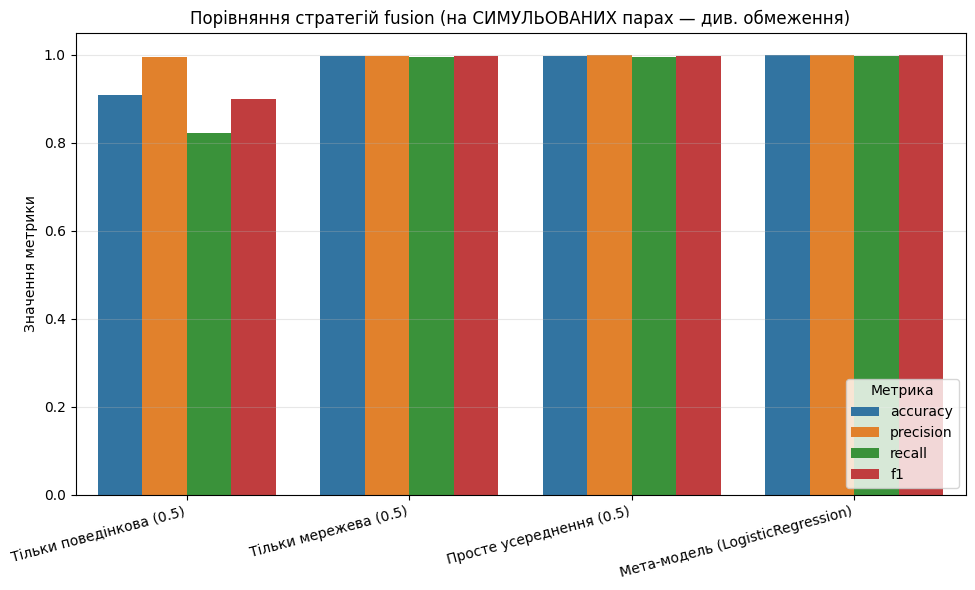

In [ ]:
plt.figure(figsize=(10, 6))
df_plot = df_results_fusion.melt(id_vars='strategy', value_vars=['accuracy', 'precision', 'recall', 'f1'],
                                  var_name='metric', value_name='value')
ax = sns.barplot(data=df_plot, x='strategy', y='value', hue='metric')
plt.title('Порівняння стратегій fusion (на СИМУЛЬОВАНИХ парах — див. обмеження)')
plt.ylabel('Значення метрики')
plt.xlabel('')
plt.ylim(0, 1.05)
plt.xticks(rotation=15, ha='right')
plt.grid(axis='y', alpha=0.3)
plt.legend(title='Метрика', loc='lower right')
plt.tight_layout()
plt.savefig(os.path.join(OUTPUT_DIR, 'figures', 'fusion_strategy_comparison.png'), dpi=300)
plt.show()

## Частина E. Матриця плутанини мета-моделі + збереження

In [ ]:
print("=== Матриця плутанини (мета-модель, симульована тестова вибірка) ===")
cm = confusion_matrix(y_sim_test, y_pred_meta)
print(pd.DataFrame(cm, index=['true_normal', 'true_bot'], columns=['pred_normal', 'pred_bot']))
print()
print(classification_report(y_sim_test, y_pred_meta, target_names=['normal/human', 'bot'], zero_division=0))

os.makedirs(f'{PROJECT_DIR}/models', exist_ok=True)
joblib.dump(meta_model, f'{PROJECT_DIR}/models/fusion_meta_logreg.pkl')
print(f"\n✅ Мета-модель збережена у {PROJECT_DIR}/models/fusion_meta_logreg.pkl")

=== Матриця плутанини (мета-модель, симульована тестова вибірка) ===
             pred_normal  pred_bot
true_normal         1499         1
true_bot               4      1496

              precision    recall  f1-score   support

normal/human       1.00      1.00      1.00      1500
         bot       1.00      1.00      1.00      1500

    accuracy                           1.00      3000
   macro avg       1.00      1.00      1.00      3000
weighted avg       1.00      1.00      1.00      3000


✅ Мета-модель збережена у /content/drive/MyDrive/man-bot-detection/models/fusion_meta_logreg.pkl


## Частина F. Підсумок і повторне застереження

Наведені вище показники демонструють МЕХАНІКУ fusion: чи покращує
комбінація двох сигналів результат порівняно з кожним окремо — ЗА
ПРИПУЩЕННЯ умовної незалежності модальностей у межах класу. Оскільки
симуляція будує пари незалежно, будь-яке покращення тут показує
теоретичну верхню межу користі від fusion у найкращому (незалежному)
випадку — не гарантовану точність на реальних парних даних, яких для
цього дослідження не існує.

Для реального застосування цієї гібридної моделі знадобився б датасет,
де для кожної сесії користувача одночасно записані і рух миші, і
мережевий трафік — це прямий напрямок майбутньої роботи (збір власного
парного датасету або симуляція в контрольованому середовищі, де обидва
канали фіксуються одночасно).

In [ ]:
print("="*70)
print("ПІДСУМОК ЕТАПУ 6")
print("="*70)
best_row = df_results_fusion.loc[df_results_fusion['f1'].idxmax()]
print(f"""
Найкраща стратегія за F1 (на симульованих даних): '{best_row['strategy']}'
  F1 = {best_row['f1']:.4f}, Accuracy = {best_row['accuracy']:.4f}

⚠️ Це демонстрація на симульованих парах під припущенням умовної
незалежності модальностей (див. Частину C і F) — не валідована на
реальних парних даних оцінка. Обов'язково зазначити це обмеження в тексті
роботи поряд з іншими обмеженнями (розділ "Обмеження" у зведеному звіті).
""")

ПІДСУМОК ЕТАПУ 6

Найкраща стратегія за F1 (на симульованих даних): 'Мета-модель (LogisticRegression)'
  F1 = 0.9983, Accuracy = 0.9983

⚠️ Це демонстрація на симульованих парах під припущенням умовної
незалежності модальностей (див. Частину C і F) — не валідована на
реальних парних даних оцінка. Обов'язково зазначити це обмеження в тексті
роботи поряд з іншими обмеженнями (розділ "Обмеження" у зведеному звіті).

